# Assignment 06: Category validation and elderly victims

**Overall purpose:** Answer the five crime-data questions on slide 11 using reproducible topic modeling and evidence-based report analysis. Your section must connect to the shared final report table and the main workstation.

## Shared rules: read before writing code

1. **Claim one assignment.** Add your name and reviewer below, then tell the group. These six notebooks are roles, not six tasks for each person.
2. **Use the shared files.** The original Parquet and shared/reports_base.parquet are read-only inputs. The base adds stable report_id values but does not clean or classify anything.
3. **Keep report_id.** Never recreate IDs after filtering, sorting or resetting an index. Join results using report_id with merge validation. URL is not a unique ID: some URLs repeat.
4. **Use one prepared version.** Member 1 must publish outputs/member_01/reports_prepared.parquet before final modeling. Preserve all source rows and mark exclusions. Everyone records that file's checksum in run_metadata.json. Prototype results on the base are exploratory and must be rerun on the agreed prepared file.
5. **Preserve alignment.** Build each text list and embedding matrix from the same filtered DataFrame in the same order. Never filter/sort text and embeddings separately.
6. **Separate analysis from evidence.** Write short code cells, show readable tables/plots, and explain actual outputs. Do not invent findings, silently fill missing districts, or treat a colored cluster plot as proof of meaningful crime types.
7. **Export to your own folder.** outputs/member_XX holds submissions; figures/member_XX holds readable figures. templates/member_XX contains empty examples and is never a finished submission.
8. **Finish with a peer review.** Everyone contributes their section, interpretation and sample reading. Member 6 coordinates validation; they do not write the entire group project.

**Your name:** Mcolisi Austine Shongwe 

**Peer reviewer:** The team

**Status:** In progress

**Prepared input version/checksum:** Pending...


## Setup and input check

Keep this notebook inside team_notebooks, or beside the shared folder. Copy the project folder when sharing it; the notebook alone does not contain the dataset.

In [2]:
from pathlib import Path
import pandas as pd
import json

In [3]:
project_folder = Path.cwd()
if not (project_folder / "shared").exists():
    project_folder = project_folder.parent

assert (project_folder / "shared/source_manifest.json").exists(), "Open the notebook from the shared project folder."

In [4]:
output_folder = project_folder / "outputs/member_06"
figure_folder = project_folder / "figures/member_06"
output_folder.mkdir(parents=True, exist_ok=True)
figure_folder.mkdir(parents=True, exist_ok=True)

In [5]:
text_columns = ["report_id", "date_posted", "title_en", "description_en", "district", "url"]
reports_base = pd.read_parquet(project_folder / "shared/reports_base.parquet", columns=text_columns)
assert reports_base["report_id"].is_unique
print("Base reports:", len(reports_base))
reports_base[["report_id", "date_posted", "title_en", "district"]].head(3)

Base reports: 5126


,report_id,date_posted,title_en,district
0,BR000000,2026-09-03,Police release wanted photo after shooting in ...,Woltmershausen
1,BR000001,2026-09-03,Burglary in Bar - Police Catch Perpetrators,Ostertor
2,BR000002,2026-09-02,Paint vandalism at high school,Horn


In [6]:
prepared_path = project_folder / "outputs/member_01/reports_prepared.parquet"
if prepared_path.exists():
    prepared_columns = text_columns + ["district_clean", "include_in_analysis", "exclusion_reason"]
    reports = pd.read_parquet(prepared_path, columns=prepared_columns)
    print("Prepared input available. Check its version before modeling.")
else:
    print("Preparation pending: final modeling and group analysis must wait for Member 1.")

Preparation pending: final modeling and group analysis must wait for Member 1.


### Check the shared source

These checks use the unchanged base snapshot. The date conversion below is only for our local review copy; Member 1 still owns the agreed prepared dataset.

In [7]:
import hashlib

pd.set_option("display.max_colwidth", None)

manifest = json.loads((project_folder / "shared/source_manifest.json").read_text())
base_sha256 = hashlib.sha256((project_folder / "shared/reports_base.parquet").read_bytes()).hexdigest()

source_checks = pd.DataFrame({
    "check": ["Expected report count", "Unique report IDs", "No missing report IDs", "Base checksum matches"],
    "passed": [len(reports_base) == manifest["row_count"], reports_base["report_id"].is_unique,
               reports_base["report_id"].notna().all(), base_sha256 == manifest["base_sha256"]]
})
assert source_checks["passed"].all(), "Stop and check the shared source version."
source_checks

,check,passed
0,Expected report count,True
1,Unique report IDs,True
2,No missing report IDs,True
3,Base checksum matches,True


In [8]:
review_reports = reports_base.copy()
review_reports["date_posted"] = pd.to_datetime(review_reports["date_posted"], errors="coerce")

input_summary = pd.Series({
    "Reports": len(review_reports),
    "Invalid or missing dates": int(review_reports["date_posted"].isna().sum()),
    "Blank titles": int(review_reports["title_en"].fillna("").str.strip().eq("").sum()),
    "Blank descriptions": int(review_reports["description_en"].fillna("").str.strip().eq("").sum()),
    "Repeated URLs after the first": int(review_reports["url"].duplicated().sum())
}, name="Count")
input_summary.to_frame()

,Count
Reports,5126
Invalid or missing dates,0
Blank titles,0
Blank descriptions,0
Repeated URLs after the first,2


**Initial check:** All four source checks passed for 5,126 reports. There are no blank titles/descriptions or invalid dates. Two URLs repeat after their first occurrence. Keep the report IDs and rows unchanged while Member 1 reviews duplicate handling.

### Check the team handovers

This table checks file availability only. Once files arrive, we must also check their schemas, IDs, statuses and prepared-input checksums before comparing models.

In [9]:
input_paths = [
    "outputs/member_01/reports_prepared.parquet",
    "outputs/member_02/nmf_titles_assignments.csv",
    "outputs/member_03/nmf_descriptions_assignments.csv",
    "outputs/member_04/bertopic_titles_assignments.csv",
    "outputs/member_04/bertopic_descriptions_assignments.csv"
]
input_readiness = pd.DataFrame({"input": input_paths})
input_readiness["available"] = [(project_folder / name).exists() for name in input_paths]
input_readiness

,input,available
0,outputs/member_01/reports_prepared.parquet,False
1,outputs/member_02/nmf_titles_assignments.csv,False
2,outputs/member_03/nmf_descriptions_assignments.csv,False
3,outputs/member_04/bertopic_titles_assignments.csv,False
4,outputs/member_04/bertopic_descriptions_assignments.csv,False


**Current dependency:** None of the five listed input files is available in this run. Final model comparison waits for the prepared data and all four model handovers. Our current outputs are source checks and draft review rules, not approved categories or elderly-victim findings.

### Packages

Use the agreed group environment. From the project folder, the setup command is `python -m pip install -r requirements.txt`. Do this only when preparing the modeling environment. The skeleton uses pandas/pyarrow; BERTopic, UMAP and HDBSCAN are not installed in the environment used to check these starter notebooks. No algorithm has been run yet.

## Things to note throughout the project

- Count reports, not confirmed incidents or individual victims. One report can discuss several events or offenses. Treat the unit consistently.
- date_posted is a publication date. The first/last years and boundary months are partial; the source's collection coverage is not established by its date range alone.
- District labels include literal None and potentially different geographic levels. Unknown district reports still matter for citywide totals; district rankings need a consistent reviewed geography.
- Categories such as Theft, Traffic-related, Assault, Burglary, Fraud and Drug-related are candidate names, not predetermined model results. Include an Unknown/Unclear option and a documented non-crime/report-type category where needed.
- A topic is a group of similar reports, not automatically a legal crime category. Several topics can map to one category; mixed topics may need a per-report review.
- Use one primary category per report for the main count tables. If the group later adopts multiple labels, document that totals can exceed the report count and rebuild all comparisons consistently.
- The source includes descriptions of harmful events. Keep relevant evidence brief in outputs, avoid unnecessary identifying details, and use report IDs/source URLs for traceability.
- No API calls, paid services, extra scraping or AI-generated embeddings are needed to start. Optional AI-assisted elderly detection needs a separate agreed method and human verification.


## Purpose and dependencies

You coordinate category validation, recommend the final model with the group, and answer Question 5 about elderly victims. Your task makes sure later counts use meaningful reviewed labels.

You can draft the category codebook and review protocol now. Model comparison needs submissions from Members 2–4; final elderly/category counts need prepared data and a selected model. Members 1 and 5 depend on your approved report_categories.csv. Everyone must help read examples and resolve disagreements: you are not the group's sole annotator.

## Our first session

Start with source verification, handover availability and draft review rules. The other analyses wait for validated shared inputs. The working age threshold is now 50+ inclusive. Victim-role checks and final counts remain pending.

### 1. Agree category and victim definitions

Draft a codebook with category definitions, inclusions/exclusions and example report IDs. Theft/Traffic-related/Assault are instructor examples, not guaranteed discoveries. Decide how to handle mixed reports and non-crime report types. Use one primary category per report for main counts. Use age 50+ inclusive as the project owner's selected working group. Record it clearly and agree how to handle elderly wording without an exact age.

#### Our current decisions

The project owner has selected **age 50+ inclusive** as our working definition. Use the label “age 50+” clearly when reporting results. These are draft review rules for discussion with the team. We will build the final category codebook from reviewed model topics and report examples.

In [10]:
elderly_age_threshold = 50
review_status = "Draft: team agreement pending"
print("Elderly age threshold:", elderly_age_threshold)
print("Review rules:", review_status)

Elderly age threshold: 50
Review rules: Draft: team agreement pending


In [11]:
review_rules = pd.DataFrame([
    ["Counting unit", "Count reports, not individual incidents or victims."],
    ["Main category", "Use one reviewed primary category per report."],
    ["Topic interpretation", "Review keywords and descriptions before naming a crime category."],
    ["Mixed or unclear reports", "Document the primary-category rule; keep unresolved cases visible."],
    ["Elderly age threshold", "Use age 50+ inclusive as our working definition; verify victim context."],
    ["Victim context", "An older suspect or witness is not evidence of an elderly victim."],
    ["Missing age evidence", "No age mention does not prove that a victim is young."],
    ["Final approval", "The team agrees definitions and model selection before labels are published."]
], columns=["decision", "draft_rule"])
review_rules

,decision,draft_rule
0,Counting unit,"Count reports, not individual incidents or victims."
1,Main category,Use one reviewed primary category per report.
2,Topic interpretation,Review keywords and descriptions before naming a crime category.
3,Mixed or unclear reports,Document the primary-category rule; keep unresolved cases visible.
4,Elderly age threshold,Use age 50+ inclusive as our working definition; verify victim context.
5,Victim context,An older suspect or witness is not evidence of an elderly victim.
6,Missing age evidence,No age mention does not prove that a victim is young.
7,Final approval,The team agrees definitions and model selection before labels are published.


**Our decision:** Use one report as the counting unit and keep unclear cases visible. The working age group is 50+. Category rules and victim-role reviews still need agreement. No final category labels or confirmed elderly-victim classifications have been assigned.

### 2. Organize a common manual review sample

Start with a manageable sample such as 120 reports. Everyone labels 20 and a second person cross-checks those reports. Preserve source IDs and record reviewer disagreement. Reserve separate development and held-out review subsets; tune/interpret on development examples and check frozen decisions on the held-out subset. Use a common eligible sample across model comparisons; document sampling and ensure rare/mixed categories are represented. Reading examples is part of everyone's workload.

#### Plan the shared reading

Propose 120 distinct reports: 60 development and 60 held-out reports. Each of six members reads 20 reports and cross-checks another 20. Sampling waits for the agreed prepared data and the common eligible cohort of all four models. Check coverage of periods and rare/mixed cases before freezing the sample. If fewer than 120 reports are jointly eligible, agree a smaller sample.

In [12]:
review_plan = pd.DataFrame({
    "review_split": ["development", "held_out"],
    "proposed_reports": [60, 60],
    "purpose": ["Develop category rules and resolve ambiguities", "Evaluate frozen rules and compare models"]
})
assert review_plan["proposed_reports"].sum() == 120
review_plan

,review_split,proposed_reports,purpose
0,development,60,Develop category rules and resolve ambiguities
1,held_out,60,Evaluate frozen rules and compare models


**Review procedure:** Keep reference readers blind to model predictions. A second reader checks each report; record disagreements and resolve them before making agreed labels. Use development examples to refine the rules. Do not use held-out agreement scores to revise the rules and then report those same scores as independent validation. The held-out labels are human-reviewed reference labels, not official ground truth.

**Our proposal:** Share 120 reports across six readers, with a second reading for every report. This is a workload and validation plan; no final review sample has been drawn yet.

### 3. Compare all four models

Load each assignments/topic/sample/run table. Validate model IDs, complete report-ID coverage, status values and prepared checksums. Compare understandable keywords/examples, topic sizes, coverage, unassigned share, parameter sensitivity and agreed labels on the same held-out reports. Label agreement is against a reviewed sample, not established official ground truth. Do not average model scores with incompatible meanings.

In [13]:
# TODO: add short code cells for this step.

**Explain your output:** What did you observe? Why does it matter? What remains uncertain?

### 4. Build mappings and select one final model

Create category_mapping.csv for every topic in all four models so comparison is possible. Interpret (model_id, topic_id) pairs, never topic IDs alone. Document merge/split/unknown decisions. Agree one selected_model_id and record reasons/approval in selected_model.json. Apply its reviewed mapping to report_categories.csv, keeping all base IDs and status values. Use Unknown/Unclear for unresolved topics. Record any report-level manual override in category_overrides.csv rather than silently editing a label.

In [14]:
# TODO: add short code cells for this step.

**Explain your output:** What did you observe? Why does it matter? What remains uncertain?

### 5. Publish the label handover

Confirm one row per base report_id, no missing IDs, consistency between selected model, mapping and categories, and a recorded prepared checksum. Check category totals plus excluded/unknown cases reconcile with the original cohort. Send the approved label version to Members 1 and 5. Any later change requires a new version and rebuilt district/time/elderly summaries.

In [15]:
# TODO: add short code cells for this step.

**Explain your output:** What did you observe? Why does it matter? What remains uncertain?

### 6. Identify candidate elderly-victim reports

Search descriptions for explicit elderly wording, pensioner/senior expressions and age patterns; read context, not keywords alone. An older witness or suspect is not an elderly victim. Keep a row for every base report with status yes/no_evidence/unclear/not_reviewed/excluded. Store a brief evidence excerpt and reason for reviewed candidates. No age mention is not proof that the victim is young. Sample negative/noncandidate reports to assess obvious misses and state search limits.

#### Screen age mentions

Use age **50+ inclusive** as our working definition. Compare it with 65+ only to show sensitivity to the cutoff. This exploratory run uses the unchanged base snapshot; it must be repeated on the agreed prepared data.

The rules match numeric expressions such as `50-year-old`, `50 year old`, `aged 50` and lists such as `aged 50 and 70`. They may miss written-out or differently formatted ages. Ranges, object ages and the role of each person still need manual review.

In [16]:
import re

report_text = review_reports["title_en"].fillna("") + " " + review_reports["description_en"].fillna("")
year_old_pattern = r"\b(\d{1,3})[\s-]+year[\s-]+olds?\b"
aged_pattern = r"\baged?\s+(\d{1,3}(?:(?:\s*,\s*|\s+and\s+|\s+to\s+|\s*-\s*)\d{1,3})*)"
word_pattern = r"\b(?:elderly|pensioners?|senior citizens?)\b"

In [17]:
def find_ages(text):
    values = re.findall(year_old_pattern, text, flags=re.I)
    for age_list in re.findall(aged_pattern, text, flags=re.I):
        values.extend(re.findall(r"\d{1,3}", age_list))
    return sorted(set(int(age) for age in values))

In [18]:
assert find_ages("A 50-year-old woman and a man aged 65.") == [50, 65]
assert find_ages("Two people aged 49 and 70.") == [49, 70]
assert find_ages("50 reports in 2026.") == []

In [19]:
screening = review_reports[["report_id", "title_en", "url"]].copy()
screening["explicit_ages"] = report_text.apply(find_ages)
screening["max_explicit_age"] = screening["explicit_ages"].apply(max, default=None).astype("Int64")

In [20]:
screening["age50plus_mention"] = screening["max_explicit_age"].ge(elderly_age_threshold).fillna(False)
screening["age65plus_mention"] = screening["max_explicit_age"].ge(65).fillna(False)
screening["elderly_wording"] = report_text.str.contains(word_pattern, case=False, regex=True)
screening["candidate"] = screening["age50plus_mention"] | screening["elderly_wording"]
screening["victim_review_status"] = "not_reviewed"

assert screening["report_id"].is_unique
assert len(screening) == len(reports_base)

#### Compare the cutoffs

Count each report once, even if an age appears in both its title and description. The 65+ set is part of the 50+ set, so the two counts must not be added. These are reports with age-pattern matches, **not confirmed elderly-victim reports**.

In [21]:
age_comparison = pd.DataFrame({
    "age_threshold": [elderly_age_threshold, 65],
    "reports_with_age_mention": [int(screening["age50plus_mention"].sum()),
                                 int(screening["age65plus_mention"].sum())]
})
additional_reports = int((screening["age50plus_mention"] & ~screening["age65plus_mention"]).sum())
assert additional_reports == age_comparison.iloc[0, 1] - age_comparison.iloc[1, 1]
age_comparison

,age_threshold,reports_with_age_mention
0,50,1201
1,65,590


In [22]:
print("Additional reports flagged by the 50+ cutoff:", additional_reports)
print("Reports with elderly wording but no detected 50+ age:",
      int((screening["elderly_wording"] & ~screening["age50plus_mention"]).sum()))
print("Total reports in the candidate review queue:", int(screening["candidate"].sum()))
print("Victim-role checks are still pending for every report.")

Additional reports flagged by the 50+ cutoff: 611
Reports with elderly wording but no detected 50+ age: 24
Total reports in the candidate review queue: 1225
Victim-role checks are still pending for every report.


In [23]:
import matplotlib.pyplot as plt

date_start = review_reports["date_posted"].min().date()
date_end = review_reports["date_posted"].max().date()
chart_note = (f"Base: {len(screening):,} reports | Published {date_start} to {date_end}\n"
              "65+ is part of 50+. Person roles are unreviewed; these are not victim counts.")

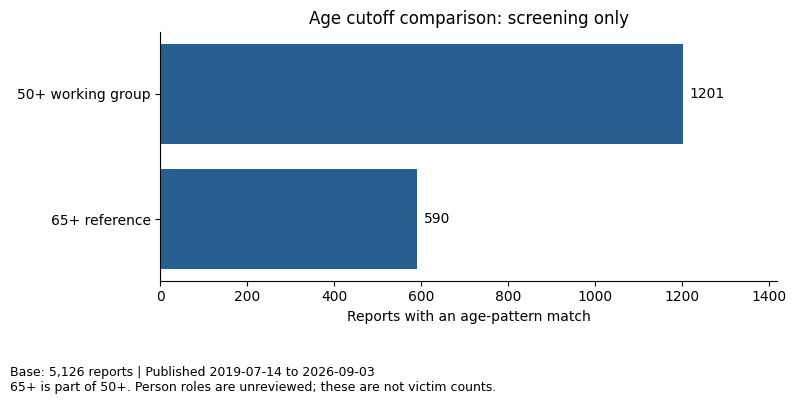

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(["50+ working group", "65+ reference"],
               age_comparison["reports_with_age_mention"], color="#285f91")
ax.bar_label(bars, padding=5)
ax.invert_yaxis()
ax.set_xlim(0, age_comparison["reports_with_age_mention"].max() * 1.18)
ax.set_xlabel("Reports with an age-pattern match")
ax.set_title("Age cutoff comparison: screening only")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, chart_note, fontsize=9)
fig.tight_layout(rect=[0, 0.14, 1, 1])
fig.savefig(figure_folder / "age_threshold_screening.png", dpi=150, bbox_inches="tight")
plt.show()

#### Prepare the review queue

A word such as “pensioner” adds a candidate for context review; it does not establish an exact age. Check the original description using the report ID or URL. Older suspects, witnesses and non-crime notices must not be counted as elderly victims.

These generated screening files are rebuilt on rerun. Keep manual decisions in the separate final review log when that stage starts.

In [25]:
candidate_queue = screening.loc[screening["candidate"]].copy()
candidate_queue["screen_reason"] = "Elderly wording; exact age and victim role need review"
candidate_queue.loc[candidate_queue["age50plus_mention"], "screen_reason"] = "Age 50+ mention; victim role needs review"
candidate_queue[["report_id", "title_en", "explicit_ages", "screen_reason"]].head(5)

,report_id,title_en,explicit_ages,screen_reason
4,BR000004,Bogus water workers steal jewelry,[89],Age 50+ mention; victim role needs review
11,BR000011,Injured with a knife,"[30, 50]",Age 50+ mention; victim role needs review
12,BR000012,Woman critically injured,"[28, 68]",Age 50+ mention; victim role needs review
14,BR000014,14-year-old screams anti-Semitic insults,"[14, 57]",Age 50+ mention; victim role needs review
15,BR000015,Police apprehends man with firearm,[56],Age 50+ mention; victim role needs review


**Screening result:** The 50+ cutoff flags 1,201 reports with age mentions, compared with 590 at 65+: 611 additional reports. Another 24 reports have elderly wording without a detected 50+ age, giving 1,225 candidates for review. These are not confirmed elderly-victim reports. The 120-report model-validation proposal is a separate task from this larger victim-review queue.

### 7. Verify candidates and summarize the findings

Have another member review all confirmed elderly-victim cases and uncertain cases. Count only confirmed yes reports, using approved crime categories and districts. Export elderly_review.csv and elderly_summary.csv. Keep no_evidence/unclear/not_reviewed counts visible; do not call the result the total incidence of crimes against older people. If evidence cannot resolve a category/district, say so rather than forcing an answer.

In [26]:
# TODO: add short code cells for this step.

**Explain your output:** What did you observe? Why does it matter? What remains uncertain?

### 8. Export the final validation handover

Submit the codebook, sample/reviews, model comparison, mappings, selected model, final labels, elderly review and summary, metadata and handover. Include a model comparison table, elderly category/district charts and evidence examples. selected_model.json must include model_id, status=approved only after agreement, prepared_sha256, category_mapping_sha256, report_categories_sha256, selection_reason and approvers. run_metadata.json records source/prepared/category checksums, group decisions, definition of elderly, search rules and versions.

#### Save our current work

These files record source checks, a **draft** protocol and exploratory age-pattern screening. They are not the final model comparison, category labels or elderly analysis. No final label files are created at this stage.

In [27]:
source_checks.to_csv(output_folder / "source_checks.csv", index=False)
input_readiness.to_csv(output_folder / "input_readiness.csv", index=False)
review_rules.to_csv(output_folder / "review_rules_draft.csv", index=False)
review_plan.to_csv(output_folder / "review_plan_draft.csv", index=False)

In [28]:
screening.to_csv(output_folder / "age50plus_screening.csv", index=False)
candidate_queue.to_csv(output_folder / "age50plus_candidates_draft.csv", index=False)
age_comparison.to_csv(output_folder / "age_threshold_comparison.csv", index=False)

In [29]:
import platform
from importlib.metadata import version

metadata = json.loads((project_folder / "templates/member_06/run_metadata.json").read_text())
metadata["author"] = "Mcolisi Austine Shongwe"
metadata["reviewer"] = "The team (review pending)"
metadata["status"] = "in_progress"
metadata["base_sha256"] = base_sha256
metadata["run_date"] = pd.Timestamp.now(tz="Europe/Berlin").isoformat()
metadata["python_version"] = platform.python_version()
metadata["package_versions"] = {name: version(name) for name in ["pandas", "pyarrow"]}

In [30]:
metadata["methods"] = ["Base source checks", "Draft review protocol", "Regex age and elderly-wording candidate screening"]
metadata["parameters"] = {
    "elderly_age_threshold": elderly_age_threshold,
    "elderly_threshold_status": "working_definition_selected_by_project_owner",
    "reference_threshold": 65,
    "proposed_review_reports": 120,
    "review_sample_status": "not_drawn_common_cohort_pending",
    "year_old_pattern": year_old_pattern,
    "aged_pattern": aged_pattern,
    "elderly_word_pattern": word_pattern
}

In [31]:
metadata["package_versions"]["matplotlib"] = version("matplotlib")
metadata["counts"] = {
    "base_reports": len(reports_base),
    "listed_inputs_available": int(input_readiness["available"].sum()),
    "reports_with_age50plus_mention": int(screening["age50plus_mention"].sum()),
    "reports_with_age65plus_mention": int(screening["age65plus_mention"].sum()),
    "additional_reports_at_50": additional_reports,
    "candidate_reports_pending_manual_review": len(candidate_queue)
}

In [32]:
metadata["notes"] = ["Age 50+ inclusive selected by the project owner; communicate the definition to the team.",
                     "Screening counts are any-role age-pattern matches, not confirmed victim counts.",
                     "Word-only candidates have no established exact age; ranges and age formatting need review.",
                     "No final crime labels or elderly-victim classifications produced; prepared/model handovers pending."]
(output_folder / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Current screening metadata saved.")

Current screening metadata saved.


In [33]:
handover = f"""# Member 6: validation and age 50+ screening
Author: Mcolisi Austine Shongwe
Status: In progress; manual victim-role review and final model work pending.
Base reports checked: {len(reports_base)}
Base SHA-256: {base_sha256}
Working definition: age {elderly_age_threshold}+ inclusive, selected by the project owner.

Completed: source checks, draft review rules/plan and automated age-pattern screening.
Age 50+ mention: {int(screening['age50plus_mention'].sum())} reports.
Age 65+ mention (reference): {int(screening['age65plus_mention'].sum())} reports.
Additional reports at 50+: {additional_reports}.
Candidate queue including elderly wording: {len(candidate_queue)} reports; all unreviewed.
Outputs: source_checks.csv, input_readiness.csv, review_rules_draft.csv, review_plan_draft.csv.
Screening files: age50plus_screening.csv, age50plus_candidates_draft.csv, age_threshold_comparison.csv.
Also saved: run_metadata.json and figures/member_06/age_threshold_screening.png.

Pending: prepared data, actual common review sample, codebook and four-model comparison.
Also pending: mappings, final labels, victim-role verification and elderly category/district counts.
Limits: age matches can describe suspects, witnesses, ranges or objects; patterns may miss other wording.
Next: communicate the 50+ definition and review candidate descriptions with another team member.
Main workstation: exploratory screening only; no confirmed elderly-victim totals to import yet.
"""
(output_folder / "handover.md").write_text(handover, encoding="utf-8")
print("Handover updated; final victim findings remain pending.")

Handover updated; final victim findings remain pending.


**Saved status:** Our source checks, draft protocol and age 50+ candidate screening are saved in outputs/member_06. The required final model and elderly-result files remain pending; draft files must not be treated as final results.

**Important limitation:** A keyword search may miss relevant reports. Report the search strategy and its reviewed coverage. Optional AI assistance must be agreed with the group, record the model/prompt, and verify its results; the skeleton does not authorize uploading report text to an external service.

## What you must submit to the main workstation

Submit this completed notebook with saved outputs, your files in outputs/member_06, and figures in figures/member_06. Run the notebook top-to-bottom before submission. Do not submit empty templates as results.

- **review_sample.csv** = columns: `report_id`, `review_split`, `reviewer`, `reference_category`, `second_reviewer`, `second_category`, `agreed_category`, `notes`.
- **category_codebook.csv** = columns: `crime_category`, `definition`, `inclusions`, `exclusions`, `example_report_id`.
- **model_comparison.csv** = columns: `model_id`, `n_topics`, `assigned_share`, `unassigned_share`, `reviewed_reports`, `matching_labels`, `label_agreement_rate`, `selection_notes`.
- **category_mapping.csv** = columns: `model_id`, `topic_id`, `crime_category`, `decision`, `reason`.
- **report_categories.csv** = columns: `report_id`, `selected_model_id`, `topic_id`, `crime_category`, `category_status`.
- **elderly_review.csv** = columns: `report_id`, `elderly_victim_status`, `evidence_excerpt`, `reason`, `reviewer`.
- **elderly_summary.csv** = columns: `crime_category`, `district_clean`, `confirmed_reports`, `reviewed_candidate_reports`, `notes`.
- **run_metadata.json** = name, input checksums, package versions, method settings, run date, record counts and status.
- **handover.md** = what you did, results, limitations, reviewer comments, output inventory and outstanding questions.
- **selected_model.json** = approved model_id, reason for selection, prepared input checksum, mapping/category checksums, approval names and status.

**Main notebook destination:** Model comparison and approved categories; Elderly victims; Final question by question conclusions.

Add category_overrides.csv if any individual labels were changed. The model-selection/category handover is an earlier milestone than the final elderly analysis; publish it promptly so Members 1 and 5 can proceed.
### Output conventions

- Keep report_id as the original BR string. Topic IDs are integers within a model, or empty for missing/excluded inputs; HDBSCAN noise is -1.
- For model tables, use the exact model_id and assignment_status values: assigned, unassigned, excluded, missing_text, invalid_embedding. Keywords can be semicolon-separated text. n_reports is the number of reports represented by that topic/status, not a score.
- Store shares/agreement rates as fractions from 0 to 1; multiply by 100 only when displaying percentages. Record which report set is the denominator. A model weight is not a calibrated category probability.
- Date keys use YYYY-MM-DD; monthly keys use YYYY-MM. Keep literal text labels intact when reading lookup CSVs (keep_default_na=False can preserve the original text None).
- Copy templates/member_XX/run_metadata.json into your output folder only when filling it with an actual run. Keep the common metadata keys, replace placeholders, and mark submitted/reviewed only when true. Record SHA-256 file versions, not just filenames.
- Final category statuses are mapped_topic/manual_override/unclear/unassigned/excluded/missing_text/invalid_embedding. Elderly review statuses are yes/no_evidence/unclear/not_reviewed/excluded. Unclear and unreviewed are not negative results.

### Final submission checks

- [ ] All expected output files are populated, or a genuine empty result is explained (for example, no anomalies met the rule).
- [ ] Every report-level table uses report_id and includes the required cohort, without unexpected duplicates.
- [ ] IDs, source/prepared checksums, categories and denominators match the shared contract.
- [ ] Required charts have descriptive titles, labels, units, periods and readable text; export PNG/HTML as appropriate.
- [ ] Code runs in order; results and explanations agree; raw/debug output is bounded.
- [ ] A peer reviewer has checked the method, sample reports, files and conclusions.
- [ ] handover.md says exactly what to import into the main notebook and lists anything still unresolved.

### Your handover summary

**What I completed:** Source checks, draft review plan and age 50+ candidate screening.  
**Most useful finding:** See the executed threshold comparison; matches still need victim-role review.  
**Output files and row counts:** See outputs/member_06/handover.md and run_metadata.json.  
**Main limitations:** Prepared/model inputs and manual victim-role reviews are pending.  
**Reviewer decision:** Pending team review.  
**Next person who needs my outputs:** The team reviews definitions and candidates; Members 1 and 5 later need approved labels.